# FFT oraz 2D DWT w rozpoznawaniu obrazów

**Autor:** Jakub Psarski <br />
**Data:** 28.10.2026

Program wyszukuje w bazie emotikonę najbardziej podobną do zapytania. Obrazy są opisywane wektorami cech: FFT (moduł widma), Haar (energie podpasm z `pywt.wavedec2`) oraz cechami hybrydowymi powstałymi z połączenia obu. Porównywane są różne sposoby fuzji cech FFT i Haar.

## Importy i parametry

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

np.random.seed(0)
WAVELET = "haar"
LEVELS = 4
N_QUERIES = 200

## Baza emotikon i zapytania

In [2]:
def make_emoji(c):
    img = np.zeros((64, 64), np.uint8)
    cv2.circle(img, (32, 32), 24, 255, -1)
    cv2.circle(img, (24, 24), 4, 0, -1)
    cv2.circle(img, (40, 24), 4, 0, -1)
    if c == 0:
        cv2.ellipse(img, (32, 36), (13, 10), 0, 0, 180, 0, -1)
    elif c == 1:
        cv2.ellipse(img, (32, 48), (12, 7), 0, 180, 360, 0, 4)
    elif c == 2:
        cv2.rectangle(img, (21, 40), (43, 44), 0, -1)
    else:
        cv2.circle(img, (32, 42), 7, 0, -1)
    return img


def transform(img):
    M = cv2.getRotationMatrix2D((32, 32), np.random.uniform(-30, 30), np.random.uniform(0.7, 1.1))
    M[0, 1] += np.random.uniform(-0.2, 0.2)
    M[:, 2] += np.random.uniform(-5, 5, 2)
    return cv2.warpAffine(img, M, (64, 64), flags=cv2.INTER_NEAREST)


names = np.array(["happy", "sad", "neutral", "surprised"])
db_labels = np.repeat(np.arange(4), 100)
db_imgs = np.array([transform(make_emoji(c)) for c in db_labels])
q_labels = np.random.randint(4, size=N_QUERIES)
q_imgs = np.array([transform(make_emoji(c)) for c in q_labels])
print("database size:", len(db_imgs))
print("queries:", len(q_imgs))

database size: 400
queries: 200


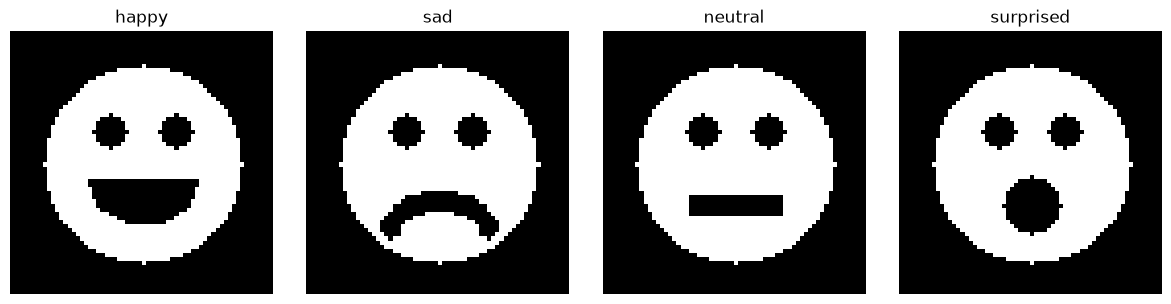

In [3]:
plt.figure(figsize=(12, 3))
for c in range(4):
    plt.subplot(1, 4, c + 1)
    plt.imshow(make_emoji(c), cmap="gray")
    plt.title(names[c])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Cechy FFT i Haar

In [4]:
def fft_features(img):
    F = np.abs(np.fft.fftshift(np.fft.fft2(img / 255.0)))
    return np.log1p(F[28:36, 28:36]).ravel()


def haar_features(img):
    coeffs = pywt.wavedec2(img / 255.0, wavelet=WAVELET, level=LEVELS)
    bands = [coeffs[0]] + [b for details in coeffs[1:] for b in details]
    return np.array([[np.abs(b).mean(), b.std()] for b in bands]).ravel()


def fft_haar_features(img):
    F = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img / 255.0))))[16:48, 16:48]
    coeffs = pywt.wavedec2(F, wavelet=WAVELET, level=2)
    return coeffs[0].ravel()

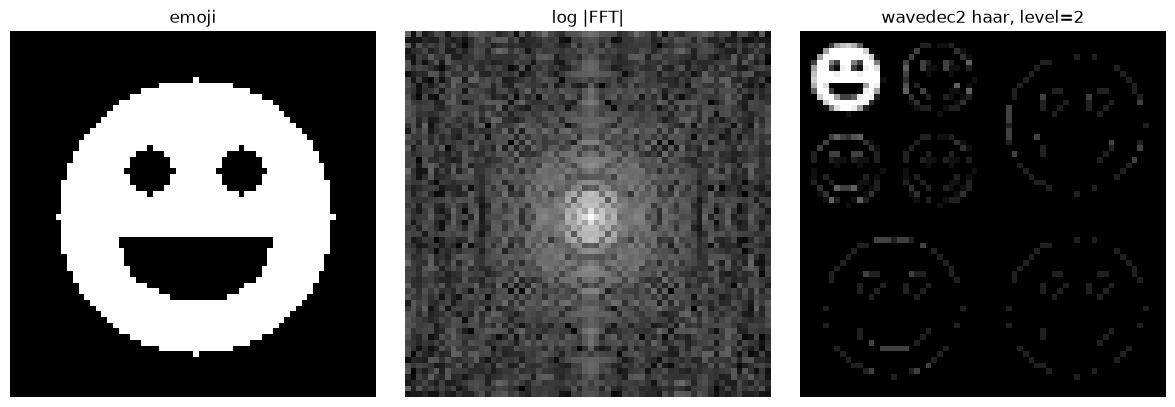

FFT features: (64,)
Haar features: (26,)
FFT->Haar features: (64,)


In [5]:
img = make_emoji(0)
coeffs = pywt.wavedec2(img / 255.0, wavelet=WAVELET, level=2)
arr, _ = pywt.coeffs_to_array([coeffs[0]] + [tuple(np.abs(b) for b in d) for d in coeffs[1:]])
spectrum = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img / 255.0))))

plt.figure(figsize=(12, 4))
for i, (im, title) in enumerate(zip([img, spectrum, arr], ["emoji", "log |FFT|", "wavedec2 haar, level=2"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

print("FFT features:", fft_features(img).shape)
print("Haar features:", haar_features(img).shape)
print("FFT->Haar features:", fft_haar_features(img).shape)

## Wyszukiwanie – odległość euklidesowa do bazy

In [6]:
def features(fn):
    D = np.array([fn(im) for im in db_imgs])
    Q = np.array([fn(im) for im in q_imgs])
    mean, std = D.mean(axis=0), D.std(axis=0) + 1e-9
    return (D - mean) / std, (Q - mean) / std


def distances(Q, D):
    return np.sqrt(((Q[:, None, :] - D[None, :, :]) ** 2).sum(axis=2))


def accuracy(dist):
    return np.mean(db_labels[dist.argmin(axis=1)] == q_labels) * 100


D_fft, Q_fft = features(fft_features)
D_haar, Q_haar = features(haar_features)
D_fh, Q_fh = features(fft_haar_features)

d_fft = distances(Q_fft, D_fft)
d_haar = distances(Q_haar, D_haar)

## Porównanie metod

- **FFT** – same cechy FFT,
- **Haar** – same cechy Haar,
- **concatenation** – fuzja wczesna: sklejenie wektorów FFT i Haar w jeden wektor,
- **sum of distances** – fuzja późna: suma odległości FFT i Haar,
- **FFT -> Haar** – fuzja kaskadowa: `wavedec2` liczone na widmie FFT.

FFT                  accuracy: 86.5%
Haar                 accuracy: 59.5%
concatenation        accuracy: 80.5%
sum of distances     accuracy: 79.0%
FFT -> Haar          accuracy: 94.5%


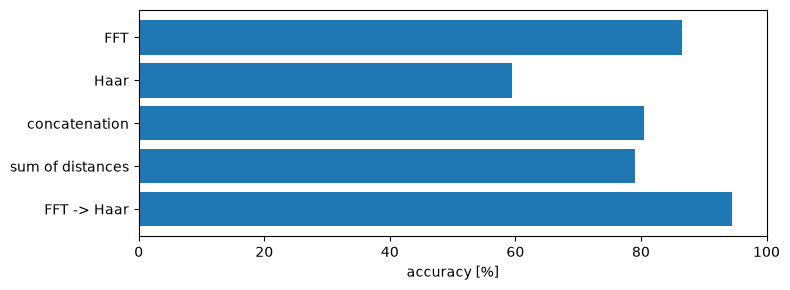

In [7]:
d_concat = distances(np.hstack([Q_fft, Q_haar]), np.hstack([D_fft, D_haar]))
d_sum = d_fft / d_fft.mean() + d_haar / d_haar.mean()
d_fh = distances(Q_fh, D_fh)

results = {
    "FFT": accuracy(d_fft),
    "Haar": accuracy(d_haar),
    "concatenation": accuracy(d_concat),
    "sum of distances": accuracy(d_sum),
    "FFT -> Haar": accuracy(d_fh),
}

for name, acc in results.items():
    print(f"{name:20s} accuracy: {acc:.1f}%")

plt.figure(figsize=(8, 3))
plt.barh(list(results.keys()), list(results.values()))
plt.xlabel("accuracy [%]")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Przykładowe wyniki wyszukiwania

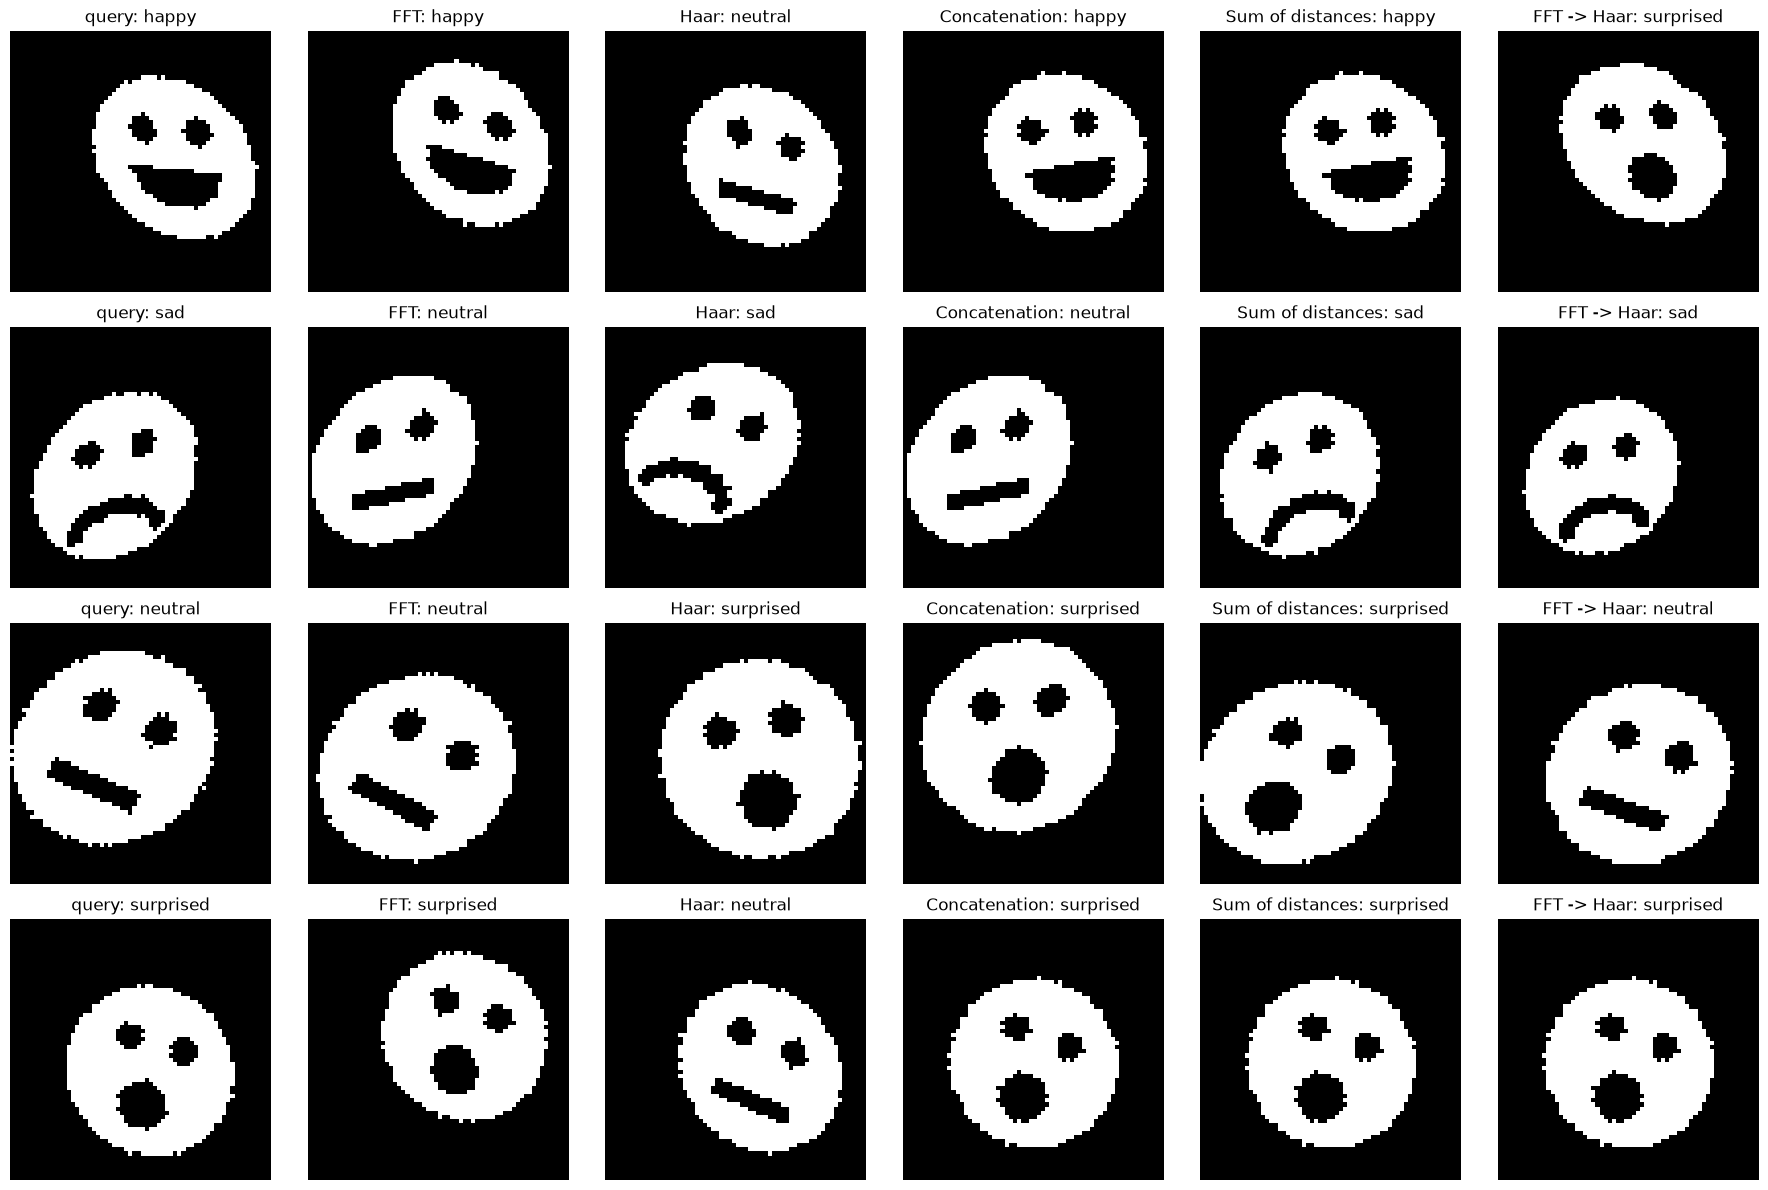

In [8]:
methods = {"FFT": d_fft, "Haar": d_haar, "Concatenation": d_concat, "Sum of distances": d_sum, "FFT -> Haar": d_fh}
examples = [np.where(q_labels == c)[0][0] for c in range(4)]

plt.figure(figsize=(18, 12))
for r, q in enumerate(examples):
    plt.subplot(4, 6, 6 * r + 1)
    plt.imshow(q_imgs[q], cmap="gray")
    plt.title("query: " + names[q_labels[q]])
    plt.axis("off")
    for k, (name, dist) in enumerate(methods.items()):
        found = dist[q].argmin()
        plt.subplot(4, 6, 6 * r + k + 2)
        plt.imshow(db_imgs[found], cmap="gray")
        plt.title(f"{name}: {names[db_labels[found]]}")
        plt.axis("off")
plt.tight_layout()
plt.show()

## Wnioski

FFT działa dobrze (86,5%), bo moduł widma nie zmienia się przy przesunięciu obrazu. Haar działa słabo (59,5%), bo energie podpasm mówią tylko, ile jest krawędzi, a nie jaki jest kształt ust. Proste łączenie FFT i Haar (sklejenie wektorów, suma odległości) daje wynik gorszy od samego FFT, bo słabe cechy Haar psują dobre cechy FFT. Najlepsza jest fuzja kaskadowa FFT -> Haar (94,5%): Haar uśrednia widmo FFT, przez co cechy są mniej wrażliwe na obrót i zmianę skali.